# Kalshi Perps: Exploratory Verification Extensions


Several sections below are explicitly flagged as nulls or noise. Continue to rerun as more data
accumulates through kalshi_perps_data.py and external_data.py because some of
what is inconclusive now may resolve with a longer history.

Loads only CSVs from kalshi_data/ and kalshi_data/external/

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("kalshi_data")
EXT = DATA / "external"

plt.rcParams.update({
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "grid.color": "#e5e5e5",
    "grid.linewidth": 0.6,
    "font.size": 10,
})

C_KALSHI = "#0072B2"     # Okabe-Ito blue
C_OKX = "#D55E00"        # vermillion
C_COINGECKO = "#009E73"  # green
C_NEUTRAL = "#4a4a4a"

In [2]:
markets = pd.read_csv(DATA / "perp_markets.csv")
contract_size = markets.set_index("ticker")["contract_size"].to_dict()

funding = pd.read_csv(DATA / "funding_rates_all.csv")
funding["funding_time"] = pd.to_datetime(funding["funding_time"], utc=True)

launch_date = funding.groupby("market_ticker")["funding_time"].min()
active_tickers = sorted(launch_date.index)

funding["days_since_launch"] = (
    funding["funding_time"] - funding["market_ticker"].map(launch_date)
).dt.total_seconds() / 86400

wave1 = ["KXBTCPERP", "KXETHPERP", "KXSOLPERP", "KXXRPPERP"]


def short_name(ticker):
    return ticker.replace("KX", "").replace("PERP", "")


def load_external(ticker):
    okx_path = EXT / f"okx_{ticker}.csv"
    cg_path = EXT / f"coingecko_{ticker}.csv"
    if not okx_path.exists() or not cg_path.exists():
        return None
    okx = pd.read_csv(okx_path, parse_dates=["timestamp"]).sort_values("timestamp")
    cg = pd.read_csv(cg_path, parse_dates=["timestamp"]).sort_values("timestamp")
    return okx, cg


def load_candles(ticker):
    path = DATA / f"candles_{ticker}_1440m.csv"
    if not path.exists():
        return None
    df = pd.read_csv(path)
    # match dtype precision of pd.read_csv(parse_dates=...) elsewhere, or
    # merge_asof rejects mixing datetime64[s] with datetime64[us]
    df["ts"] = pd.to_datetime(df["end_period_ts"], unit="s", utc=True).astype("datetime64[us, UTC]")
    return df

## 1. Is Kalshi a segmented market?

Kalshi's mark_price is per-contract, not per-coin (e.g. one BTC contract =
0.0001 BTC) — dividing by contract_size gives an implied per-coin price
comparable to external venues. We compare that to OKX's perp price (same
instrument type, offshore venue) and CoinGecko's spot price (venue-independent),
matched to each Kalshi funding timestamp (nearest, within a 2h tolerance).

Binance and Bybit's public market-data endpoints both refused this connection
on geo/compliance grounds — OKX is the offshore-perp stand-in.

In [3]:
def build_basis(ticker):
    ext = load_external(ticker)
    if ext is None:
        return None
    okx, cg = ext

    k = funding[funding["market_ticker"] == ticker].sort_values("funding_time").copy()
    k["kalshi_implied"] = k["mark_price"] / contract_size[ticker]

    merged = pd.merge_asof(
        k, okx.rename(columns={"close": "okx_price"})[["timestamp", "okx_price"]],
        left_on="funding_time", right_on="timestamp",
        direction="nearest", tolerance=pd.Timedelta("2h"),
    )
    merged = pd.merge_asof(
        merged, cg.rename(columns={"price": "coingecko_price"}),
        left_on="funding_time", right_on="timestamp",
        direction="nearest", tolerance=pd.Timedelta("2h"), suffixes=("", "_cg"),
    )
    merged["basis_okx_bps"] = (merged["kalshi_implied"] / merged["okx_price"] - 1) * 1e4
    merged["basis_cg_bps"] = (merged["kalshi_implied"] / merged["coingecko_price"] - 1) * 1e4
    return merged


basis_data = {t: build_basis(t) for t in wave1}
for t, d in basis_data.items():
    print(t, "rows with matched external data:", 0 if d is None else d["okx_price"].notna().sum())

KXBTCPERP rows with matched external data: 214
KXETHPERP rows with matched external data: 214
KXSOLPERP rows with matched external data: 214
KXXRPPERP rows with matched external data: 214


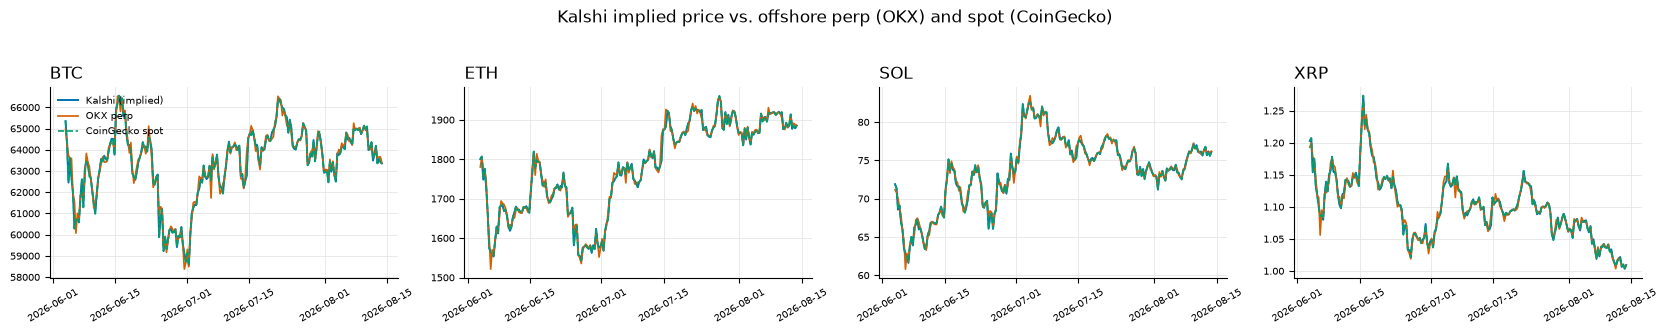

In [4]:
fig, axes = plt.subplots(1, len(wave1), figsize=(4.2 * len(wave1), 3.2))

for ax, ticker in zip(axes, wave1):
    d = basis_data[ticker]
    if d is None or d.empty:
        ax.axis("off")
        continue
    ax.plot(d["funding_time"], d["kalshi_implied"], color=C_KALSHI, linewidth=1.4, label="Kalshi (implied)")
    ax.plot(d["funding_time"], d["okx_price"], color=C_OKX, linewidth=1.2, label="OKX perp")
    ax.plot(d["funding_time"], d["coingecko_price"], color=C_COINGECKO, linewidth=1.2,
            linestyle="--", label="CoinGecko spot")
    ax.set_title(short_name(ticker), loc="left")
    ax.tick_params(axis="x", labelrotation=30, labelsize=7)
    ax.tick_params(axis="y", labelsize=7)

axes[0].legend(fontsize=7, frameon=False, loc="upper left")
fig.suptitle("Kalshi implied price vs. offshore perp (OKX) and spot (CoinGecko)", y=1.03)
fig.tight_layout()
plt.show()

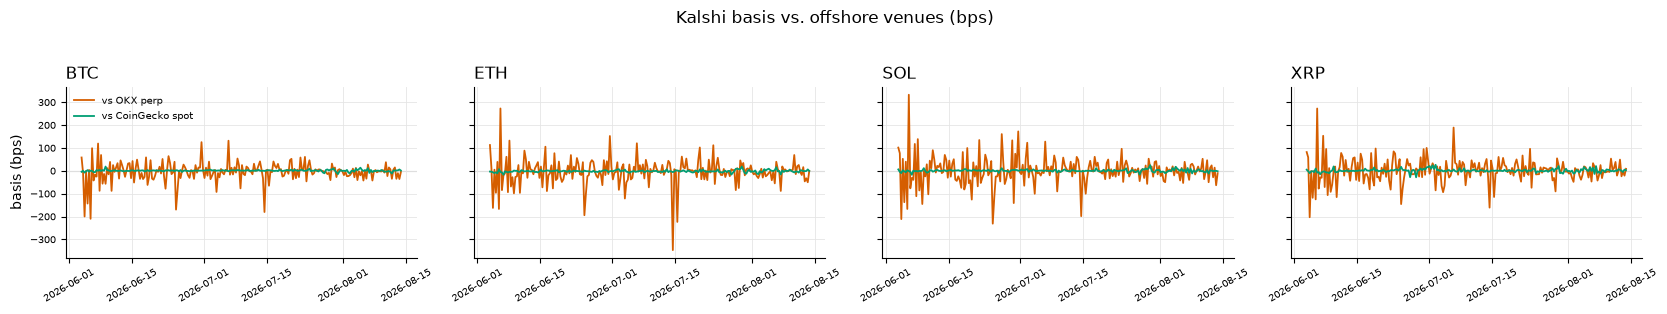

In [5]:
fig, axes = plt.subplots(1, len(wave1), figsize=(4.2 * len(wave1), 3.0), sharey=True)

for ax, ticker in zip(axes, wave1):
    d = basis_data[ticker]
    if d is None or d.empty:
        ax.axis("off")
        continue
    ax.axhline(0, color="#bbbbbb", linewidth=0.8, zorder=0)
    ax.plot(d["funding_time"], d["basis_okx_bps"], color=C_OKX, linewidth=1.3, label="vs OKX perp")
    ax.plot(d["funding_time"], d["basis_cg_bps"], color=C_COINGECKO, linewidth=1.3, label="vs CoinGecko spot")
    ax.set_title(short_name(ticker), loc="left")
    ax.tick_params(axis="x", labelrotation=30, labelsize=7)
    ax.tick_params(axis="y", labelsize=7)

axes[0].set_ylabel("basis (bps)")
axes[0].legend(fontsize=7, frameon=False, loc="upper left")
fig.suptitle("Kalshi basis vs. offshore venues (bps)", y=1.03)
fig.tight_layout()
plt.show()

## 2. Diagnostic: is the OKX basis noise real, or a matching artifact?

Section 1 showed basis-vs-OKX swinging far wider than basis-vs-CoinGecko. Two
competing explanations verified:

1. **Real**: CoinGecko is a multi-exchange aggregate (smoothed by construction),
   while OKX is one venue with its own idiosyncratic funding-driven noise.
2. **Artifact**: the `merge_asof(..., tolerance="2h")` nearest-match could be
   pairing Kalshi's snapshot with a stale OKX/CoinGecko price, and if the two
   sources have different effective match quality, that alone would produce a
   noise difference unrelated to venue economics.

In [6]:
def diagnostic_match(ticker):
    ext = load_external(ticker)
    if ext is None:
        return None
    okx, cg = ext
    k = funding[funding["market_ticker"] == ticker].sort_values("funding_time")[["funding_time"]].copy()

    okx_m = pd.merge_asof(k, okx[["timestamp", "close"]], left_on="funding_time",
                           right_on="timestamp", direction="nearest", tolerance=pd.Timedelta("2h"))
    okx_m["gap_min"] = (okx_m["funding_time"] - okx_m["timestamp"]).abs().dt.total_seconds() / 60

    cg_m = pd.merge_asof(k, cg[["timestamp", "price"]], left_on="funding_time",
                          right_on="timestamp", direction="nearest", tolerance=pd.Timedelta("2h"))
    cg_m["gap_min"] = (cg_m["funding_time"] - cg_m["timestamp"]).abs().dt.total_seconds() / 60

    return okx_m["gap_min"], cg_m["gap_min"]


print(f"{'ticker':8} {'okx median gap (min)':>22} {'cg median gap (min)':>22}")
for t in wave1:
    okx_gap, cg_gap = diagnostic_match(t)
    print(f"{short_name(t):8} {okx_gap.median():22.1f} {cg_gap.median():22.1f}")

ticker     okx median gap (min)    cg median gap (min)
BTC                         0.0                    0.0
ETH                         0.0                    0.0
SOL                         0.0                    0.0
XRP                         0.0                    0.0


In [7]:
print(f"{'ticker':8} {'corr(gap, |basis_okx|)':>24} {'OKX hourly vol (bps)':>22} {'CoinGecko hourly vol (bps)':>28}")
for t in wave1:
    d = basis_data[t].dropna(subset=["okx_price", "coingecko_price"]).copy()
    okx_gap, _ = diagnostic_match(t)
    d = d.assign(gap_min=okx_gap.reindex(d.index))
    with np.errstate(invalid="ignore"):
        corr = d["gap_min"].corr(d["basis_okx_bps"].abs())

    okx, cg = load_external(t)
    okx_vol = okx["close"].pct_change().std() * 1e4
    cg_vol = cg["price"].pct_change().std() * 1e4

    print(f"{short_name(t):8} {corr:24.3f} {okx_vol:22.1f} {cg_vol:28.1f}")

ticker     corr(gap, |basis_okx|)   OKX hourly vol (bps)   CoinGecko hourly vol (bps)
BTC                           nan                   44.2                         44.0
ETH                           nan                   58.0                         57.1
SOL                           nan                   64.9                         64.6
XRP                           nan                   55.2                         55.0


In [8]:
# Match gaps are ~0 and OKX's own volatility ~ CoinGecko's own volatility, so neither
# timestamp misalignment nor "OKX is inherently noisier" explains the wider OKX basis.
# Third hypothesis: OKX perp price is itself spot + OKX's own funding-driven basis, so
# comparing Kalshi to OKX stacks two independent basis processes, while comparing Kalshi
# to CoinGecko (spot) only reflects Kalshi's own basis. Test directly.
print(f"{'ticker':8} {'std(Kalshi vs OKX) bps':>24} {'std(Kalshi vs CoinGecko) bps':>30} {'std(OKX vs CoinGecko) bps':>27}")
for t in wave1:
    d = basis_data[t].dropna(subset=["okx_price", "coingecko_price"]).copy()
    d["okx_vs_cg_bps"] = (d["okx_price"] / d["coingecko_price"] - 1) * 1e4
    print(f"{short_name(t):8} {d['basis_okx_bps'].std():24.1f} "
          f"{d['basis_cg_bps'].std():30.1f} {d['okx_vs_cg_bps'].std():27.1f}")

ticker     std(Kalshi vs OKX) bps   std(Kalshi vs CoinGecko) bps   std(OKX vs CoinGecko) bps
BTC                          43.2                            3.7                        43.5
ETH                          57.7                            4.7                        58.3
SOL                          62.5                            5.1                        61.7
XRP                          53.3                            7.1                        53.5


**Result:** `std(Kalshi vs OKX)` matches `std(OKX vs CoinGecko)` almost exactly
for every wave-1 ticker, while `std(Kalshi vs CoinGecko)` is an order of
magnitude smaller. The "noise" was OKX's own basis-to-spot wobble, not Kalshi's.
Kalshi's `mark_price` tracks spot far tighter than OKX's perp price tracks spot.

That's a striking claim for a two-month-old, thin, single-venue market — striking
enough to be suspicious. Section 3 checks whether it's genuine price discovery
or a mechanical artifact of how `mark_price` is computed.

## 3. Verification: is the tight tracking real, or a mark-price artifact?

`mark_price` (from the funding endpoint) is a modeled index price Kalshi
computes, not necessarily the price anyone actually traded at. If Kalshi's
mark-price formula heavily anchors to its own reference index by construction,
tight mark-vs-spot tracking would be near-tautological rather than a genuine
market-quality result.

Compare spot to Kalshi's actual daily traded price and **bid/ask
midpoint** (from candles — real market data, not a modeled index) instead of
`mark_price`, at the same daily frequency, for the same wave-1 tickers. If
traded/bid-ask basis is comparably tight to mark-price basis, the result is
real. If it's much wider (more OKX-like), `mark_price` is doing most of the
smoothing on its own, independent of what actually traded.

In [9]:
def build_daily_basis(ticker):
    candles = load_candles(ticker)
    ext = load_external(ticker)
    if candles is None or ext is None:
        return None
    _, cg = ext
    csize = contract_size[ticker]

    df = candles.sort_values("ts").copy()
    df["traded_implied"] = df["price.close"] / csize
    df["bidask_mid_implied"] = (df["bid.close"] + df["ask.close"]) / 2 / csize

    df = pd.merge_asof(
        df, cg.rename(columns={"price": "coingecko_price"}),
        left_on="ts", right_on="timestamp",
        direction="nearest", tolerance=pd.Timedelta("6h"),
    )

    # mark_price must be matched point-in-time (nearest funding reading to the
    # candle's own timestamp), not a same-day average -- averaging a day of mark
    # readings and then comparing to a single point-in-time spot price would
    # inflate the apparent basis on any day the asset trended, with nothing to
    # do with how well mark_price actually tracks spot.
    k = funding[funding["market_ticker"] == ticker].sort_values("funding_time").copy()
    k["mark_implied"] = k["mark_price"] / csize
    df = pd.merge_asof(
        df, k[["funding_time", "mark_implied"]],
        left_on="ts", right_on="funding_time",
        direction="nearest", tolerance=pd.Timedelta("6h"),
    )

    df["basis_mark_bps"] = (df["mark_implied"] / df["coingecko_price"] - 1) * 1e4
    df["basis_traded_bps"] = (df["traded_implied"] / df["coingecko_price"] - 1) * 1e4
    df["basis_bidask_bps"] = (df["bidask_mid_implied"] / df["coingecko_price"] - 1) * 1e4
    return df


daily_basis = {t: build_daily_basis(t) for t in wave1}
print(f"{'ticker':8} {'std mark-vs-spot (bps)':>24} {'std traded-vs-spot (bps)':>26} {'std bid/ask mid-vs-spot (bps)':>30}")
for t in wave1:
    d = daily_basis[t]
    if d is None:
        continue
    print(f"{short_name(t):8} {d['basis_mark_bps'].std():24.1f} "
          f"{d['basis_traded_bps'].std():26.1f} {d['basis_bidask_bps'].std():30.1f}")

ticker     std mark-vs-spot (bps)   std traded-vs-spot (bps)  std bid/ask mid-vs-spot (bps)
BTC                           3.0                        3.2                            3.5
ETH                           3.5                        3.9                            3.8
SOL                           3.9                        6.2                            4.4
XRP                           6.6                        7.5                            6.6


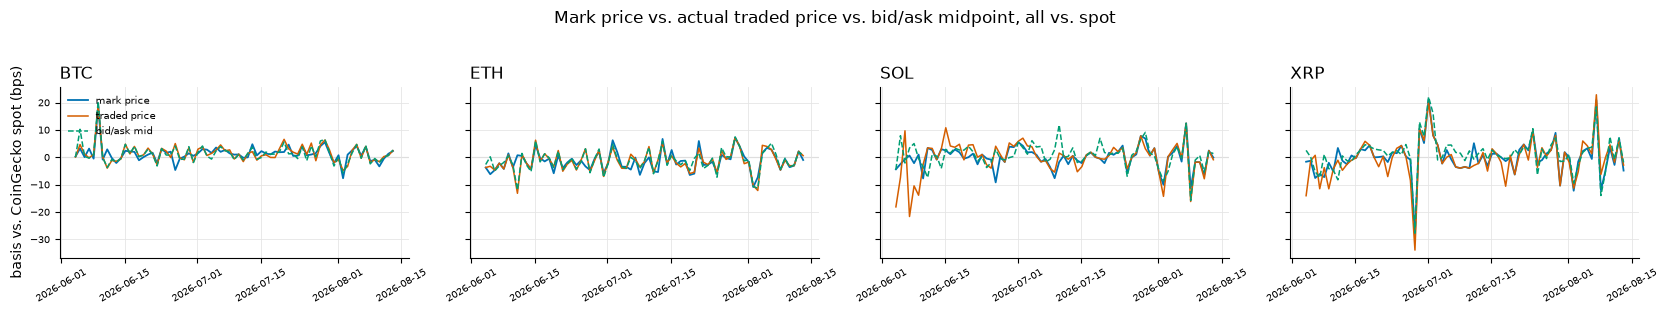

In [10]:
fig, axes = plt.subplots(1, len(wave1), figsize=(4.2 * len(wave1), 3.0), sharey=True)

for ax, ticker in zip(axes, wave1):
    d = daily_basis[ticker]
    if d is None or d.empty:
        ax.axis("off")
        continue
    ax.axhline(0, color="#bbbbbb", linewidth=0.8, zorder=0)
    ax.plot(d["ts"], d["basis_mark_bps"], color=C_KALSHI, linewidth=1.3, label="mark price")
    ax.plot(d["ts"], d["basis_traded_bps"], color=C_OKX, linewidth=1.1, label="traded price")
    ax.plot(d["ts"], d["basis_bidask_bps"], color=C_COINGECKO, linewidth=1.1, linestyle="--", label="bid/ask mid")
    ax.set_title(short_name(ticker), loc="left")
    ax.tick_params(axis="x", labelrotation=30, labelsize=7)
    ax.tick_params(axis="y", labelsize=7)

axes[0].set_ylabel("basis vs. CoinGecko spot (bps)")
axes[0].legend(fontsize=7, frameon=False, loc="upper left")
fig.suptitle("Mark price vs. actual traded price vs. bid/ask midpoint, all vs. spot", y=1.03)
fig.tight_layout()
plt.show()

## 4. Liquidity ramp-up: open interest since inception

From Kalshi's own daily candles, open interest by days-since-launch, per market.

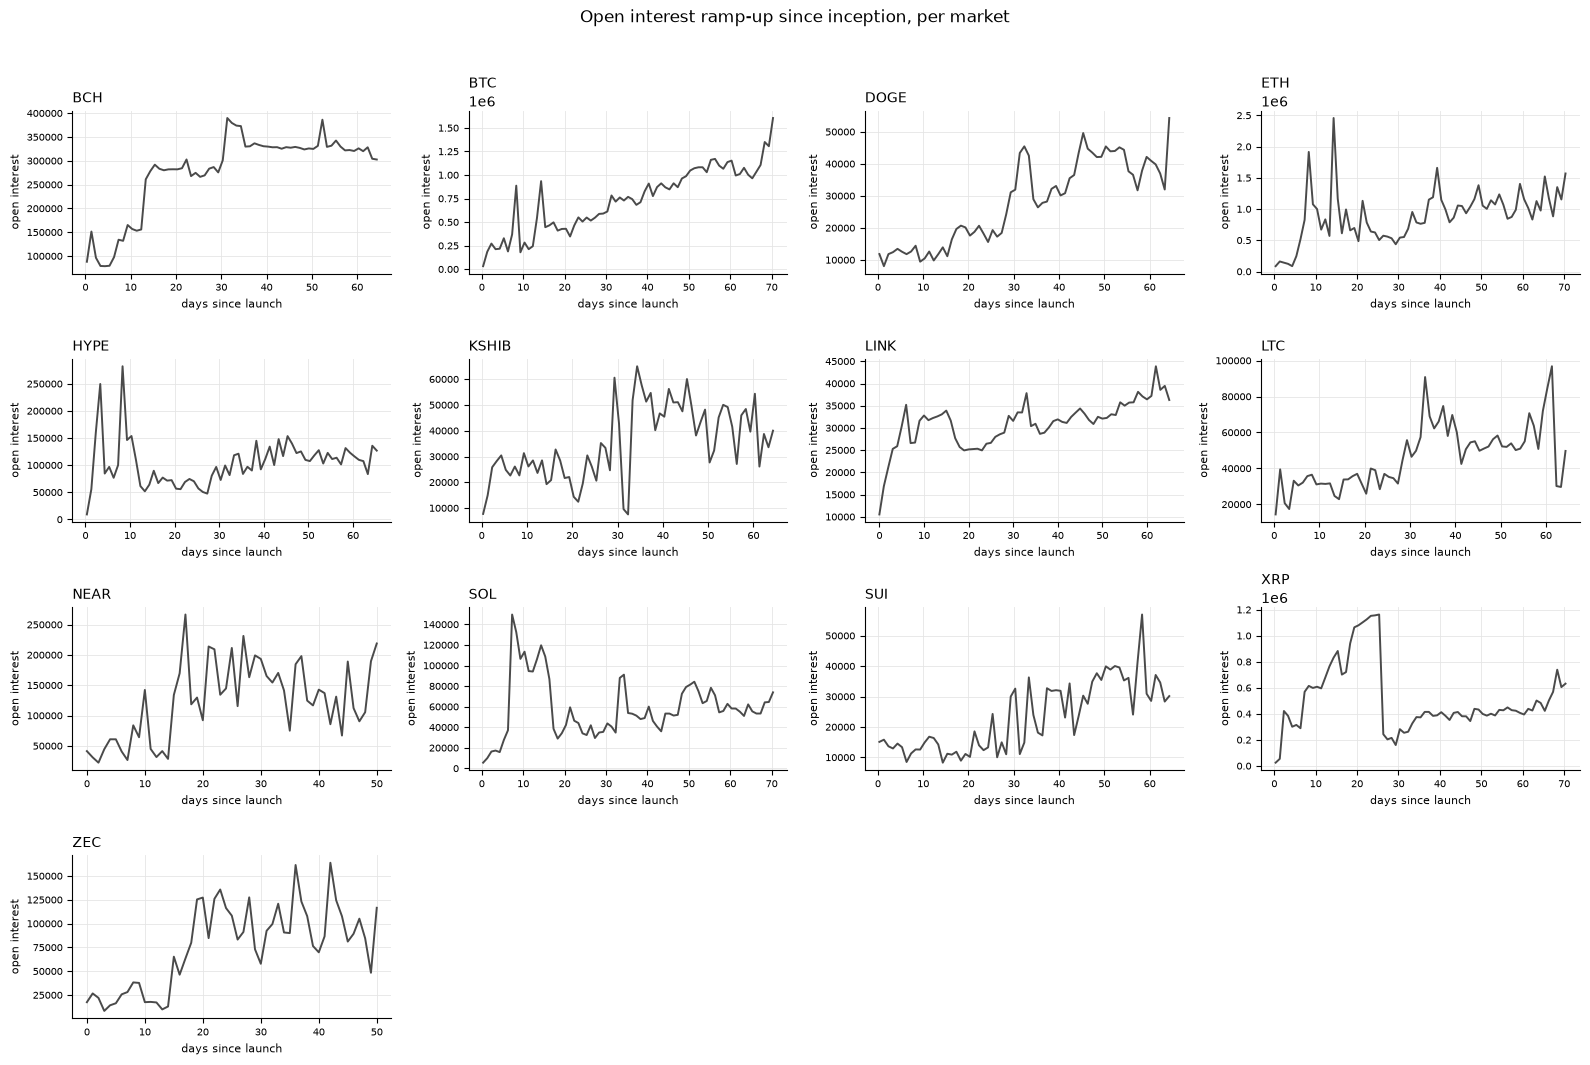

In [11]:
ncols = 4
nrows = -(-len(active_tickers) // ncols)
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 2.6 * nrows))
axes = axes.flatten()

for ax, ticker in zip(axes, active_tickers):
    df = load_candles(ticker)
    if df is None or df.empty:
        ax.axis("off")
        continue
    days = (df["ts"] - launch_date[ticker]).dt.total_seconds() / 86400
    ax.plot(days, df["open_interest"], color=C_NEUTRAL, linewidth=1.4)
    ax.set_title(short_name(ticker), fontsize=10, loc="left")
    ax.set_xlabel("days since launch", fontsize=8)
    ax.set_ylabel("open interest", fontsize=8)
    ax.tick_params(labelsize=7)

for ax in axes[len(active_tickers):]:
    ax.axis("off")

fig.suptitle("Open interest ramp-up since inception, per market", y=1.02)
fig.tight_layout()
plt.show()

## 5. Does prior offshore liquidity ("familiarity") predict faster settling?

Flagged result: this is a null. Regress `|funding_rate|` on days-since-launch,
a wave-1 dummy, and their interaction, pooled across all markets, HC1 robust
standard errors. The pooled time trend is significant; the familiarity split is
not (p=0.43 level, p=0.90 interaction) — at n=13 markets / ~2 months this may
just be underpowered rather than truly absent.

In [12]:
import statsmodels.formula.api as smf

reg_df = funding[funding["market_ticker"].isin(active_tickers)].copy()
reg_df["familiar"] = reg_df["market_ticker"].isin(wave1).astype(int)
reg_df["abs_funding_bps"] = reg_df["funding_rate"].abs() * 1e4

model = smf.ols("abs_funding_bps ~ days_since_launch * familiar", data=reg_df).fit(cov_type="HC1")
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:        abs_funding_bps   R-squared:                       0.070
Model:                            OLS   Adj. R-squared:                  0.069
Method:                 Least Squares   F-statistic:                     49.76
Date:                Sun, 30 Aug 2026   Prob (F-statistic):           3.02e-31
Time:                        20:48:57   Log-Likelihood:                -3163.5
No. Observations:                2539   AIC:                             6335.
Df Residuals:                    2535   BIC:                             6358.
Df Model:                           3                                         
Covariance Type:                  HC1                                         
                                 coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------------------------------------------------
Intercept           

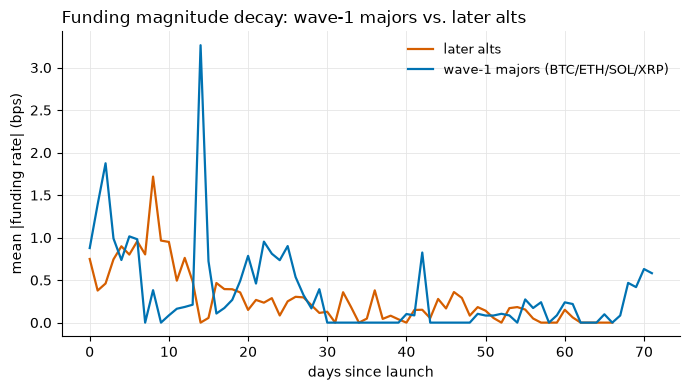

In [13]:
reg_df["day_bin"] = reg_df["days_since_launch"].astype(int)
binned = reg_df.groupby(["day_bin", "familiar"])["abs_funding_bps"].mean().unstack("familiar")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(binned.index, binned[0], color=C_OKX, linewidth=1.6, label="later alts")
ax.plot(binned.index, binned[1], color=C_KALSHI, linewidth=1.6, label="wave-1 majors (BTC/ETH/SOL/XRP)")
ax.set_xlabel("days since launch")
ax.set_ylabel("mean |funding rate| (bps)")
ax.legend(frameon=False, fontsize=9)
ax.set_title("Funding magnitude decay: wave-1 majors vs. later alts", loc="left")
fig.tight_layout()
plt.show()

## 6. Cross-market funding comovement

He et al.'s Table 5 finds strong cross-coin correlation in the futures-spot
deviation on Binance and attributes it to a common arbitrageur-funding-constraint
factor. Same test here, in calendar time (not event time, since a common factor
should be about *when*, not days-since-each-market's-own-launch): correlate
daily mean funding rate across all 13 Kalshi markets.

**Flagged result:** mean pairwise correlation came out much weaker than He et
al.'s Binance numbers (~0.10 vs. their 0.5-0.9 range) — the opposite of what
was hypothesized going in (a thinner single venue was expected to show
*stronger* comovement). Plausible reading: no mature cross-market arbitrage
community exists on Kalshi yet, so each market's funding is still driven mostly
by its own idiosyncratic launch dynamics rather than a shared factor. Could
also just be low power (52 days, many pairs with limited overlap).

78/78 pairs have enough overlapping days to compute a correlation (short-lived, staggered launches leave some pairs with little/no shared history)


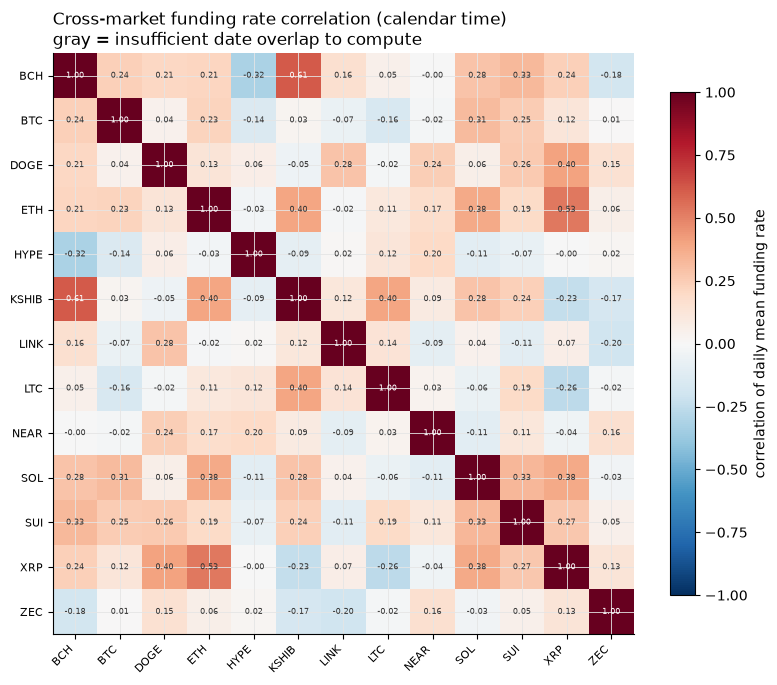

mean pairwise correlation: 0.097   median: 0.082


In [14]:
funding["date"] = funding["funding_time"].dt.date
daily = funding[funding["market_ticker"].isin(active_tickers)].pivot_table(
    index="date", columns="market_ticker", values="funding_rate", aggfunc="mean"
)
daily.columns = [short_name(c) for c in daily.columns]
corr = daily.corr()

n_pairs = len(corr) * (len(corr) - 1) // 2
n_valid = corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool)).notna().sum().sum()
print(f"{n_valid}/{n_pairs} pairs have enough overlapping days to compute a correlation "
      f"(short-lived, staggered launches leave some pairs with little/no shared history)")

cmap = plt.cm.RdBu_r.copy()
cmap.set_bad("#e5e5e5")

fig, ax = plt.subplots(figsize=(8, 7))
im = ax.imshow(corr.values, cmap=cmap, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticklabels(corr.columns, fontsize=8)

for i in range(len(corr)):
    for j in range(len(corr)):
        v = corr.values[i, j]
        label = "--" if np.isnan(v) else f"{v:.2f}"
        color = "#333333" if np.isnan(v) or abs(v) <= 0.6 else "white"
        ax.text(j, i, label, ha="center", va="center", fontsize=6, color=color)

fig.colorbar(im, ax=ax, label="correlation of daily mean funding rate", shrink=0.8)
ax.set_title("Cross-market funding rate correlation (calendar time)\n"
              "gray = insufficient date overlap to compute", loc="left")
fig.tight_layout()
plt.show()

offdiag = corr.values[~np.eye(len(corr), dtype=bool)]
print(f"mean pairwise correlation: {np.nanmean(offdiag):.3f}   median: {np.nanmedian(offdiag):.3f}")

## 7. Does liquidity formation predict price-discovery speed?

**Flagged result: noise.** Per market: "days to reach half of eventual peak open
interest" (from candles) vs. "days since launch of the *last* funding
observation with |funding| above a 0.05% settled threshold" (from funding rows).
n=13, correlation came out the opposite sign from hypothesized and is dominated
by a single outlier (ETH). Not a finding — included for completeness.

In [15]:
SETTLED_THRESHOLD = 0.0005  # 0.05%

rows = []
for ticker in active_tickers:
    df = load_candles(ticker)
    if df is None or df.empty:
        continue
    peak_oi = df["open_interest"].max()
    days_oi = (df["ts"] - launch_date[ticker]).dt.total_seconds() / 86400
    reached = days_oi[df["open_interest"] >= 0.5 * peak_oi]
    if reached.empty:
        continue
    days_to_half_oi = reached.iloc[0]

    sub = funding[funding["market_ticker"] == ticker].sort_values("days_since_launch")
    big_moves = sub[sub["funding_rate"].abs() > SETTLED_THRESHOLD]
    days_last_big_move = big_moves["days_since_launch"].max() if not big_moves.empty else 0.0

    rows.append((short_name(ticker), days_to_half_oi, days_last_big_move))

speed_df = pd.DataFrame(rows, columns=["ticker", "days_to_half_oi", "days_last_big_funding_move"])
corr_speed = speed_df["days_to_half_oi"].corr(speed_df["days_last_big_funding_move"])
print(speed_df.to_string(index=False))
print(f"\ncorrelation: {corr_speed:.3f}")

ticker  days_to_half_oi  days_last_big_funding_move
   BCH        13.333333                    6.666667
   BTC         8.333333                   14.666667
  DOGE        29.333333                    0.000000
   ETH         8.333333                   42.666667
  HYPE         2.333333                    8.333333
 KSHIB        16.333333                    0.000000
  LINK         3.000000                    0.000000
   LTC        29.333333                    0.000000
  NEAR        10.000000                    0.000000
   SOL         7.333333                   14.666667
   SUI        29.333333                    0.000000
   XRP         8.333333                   14.666667
   ZEC        19.000000                    0.000000

correlation: -0.437


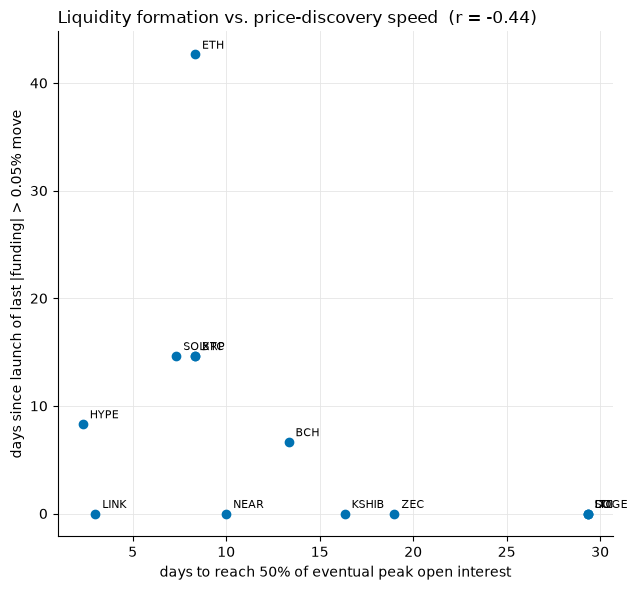

In [16]:
fig, ax = plt.subplots(figsize=(6.5, 6))
ax.scatter(speed_df["days_to_half_oi"], speed_df["days_last_big_funding_move"],
           s=36, color=C_KALSHI, zorder=3)
for _, row in speed_df.iterrows():
    ax.annotate(row["ticker"], (row["days_to_half_oi"], row["days_last_big_funding_move"]),
                fontsize=8, xytext=(5, 4), textcoords="offset points")

ax.set_xlabel("days to reach 50% of eventual peak open interest")
ax.set_ylabel("days since launch of last |funding| > 0.05% move")
ax.set_title(f"Liquidity formation vs. price-discovery speed  (r = {corr_speed:.2f})", loc="left")
fig.tight_layout()
plt.show()

## 8. Reverse-engineering Kalshi's funding clamp

Most exchanges (Binance included, per He et al.'s Appendix B) pin funding to a
small fixed rate unless the underlying premium exceeds a clamp width, rather
than paying the raw premium every period. Kalshi's funding sits at exactly 0.0
very often — check the nonzero values for a floor/wall and for repeated exact
values (a sign of quantization/rounding rather than a continuously-varying
premium).

In [17]:
all_funding = funding.loc[funding["market_ticker"].isin(active_tickers), "funding_rate"]
zero_share = (all_funding == 0).mean()
nonzero = all_funding[all_funding != 0]

print(f"share exactly 0.0: {zero_share:.1%}")
print(f"nonzero observations: {len(nonzero)}")
print(f"smallest |nonzero| value: {nonzero.abs().min():.6f} ({nonzero.abs().min()*1e4:.2f} bps)")
print(f"unique nonzero values: {nonzero.nunique()}")
print("\nmost frequent nonzero funding_rate values:")
print((nonzero * 1e4).round(2).value_counts().head(10))

share exactly 0.0: 82.4%
nonzero observations: 447
smallest |nonzero| value: 0.000100 (1.00 bps)
unique nonzero values: 447

most frequent nonzero funding_rate values:
funding_rate
 1.00    11
 1.01     7
-1.18     7
-1.07     7
-1.22     6
-1.15     6
-1.11     6
-1.52     6
-1.05     5
-1.28     5
Name: count, dtype: int64


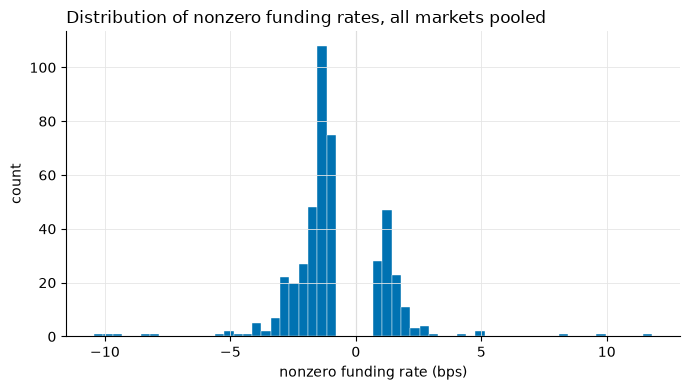

In [18]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(nonzero * 1e4, bins=60, color=C_KALSHI, edgecolor="white", linewidth=0.3)
ax.axvline(0, color="#bbbbbb", linewidth=0.8, zorder=0)
ax.set_xlabel("nonzero funding rate (bps)")
ax.set_ylabel("count")
ax.set_title("Distribution of nonzero funding rates, all markets pooled", loc="left")
fig.tight_layout()
plt.show()